In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


GPU available: True
GPU name: Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

DATA_ROOT = "/content/drive/MyDrive/Plant_Disease_HW2_C2"

print("Folder exists:", os.path.exists(DATA_ROOT))

if os.path.exists(DATA_ROOT):
    print("Contents:", os.listdir(DATA_ROOT))


Folder exists: True
Contents: ['splits', 'config', 'prepared_data']


In [4]:

import os

DATA_ROOT = "/content/drive/MyDrive/Plant_Disease_HW2_C2"

print("Folder exists:", os.path.exists(DATA_ROOT))

if os.path.exists(DATA_ROOT):
    print("\nMain folders:")
    print(os.listdir(DATA_ROOT))

    print("\nPrepared data:")
    print(os.listdir(os.path.join(DATA_ROOT, "prepared_data")))

    print("\nSplit files:")
    print(os.listdir(os.path.join(DATA_ROOT, "splits")))

    print("\nConfiguration files:")
    print(os.listdir(os.path.join(DATA_ROOT, "config")))


Folder exists: True

Main folders:
['splits', 'config', 'prepared_data']

Prepared data:
['train', 'valid', 'plantdoc_test']

Split files:
['raw_index.csv', 'train.csv', 'valid.csv', 'test.csv']

Configuration files:
['class_weights.pt', 'class_to_idx.json', 'project_config.json']


In [6]:

import os
import zipfile

zip_path = "/content/Plant-Disease-Classification-HW2-6.-main.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/")

print("ZIP extracted successfully!")

print(os.listdir("/content/"))


ZIP extracted successfully!
['.config', 'Plant-Disease-Classification-HW2-6.-main', 'Plant-Disease-Classification-HW2-6.-main.zip', 'drive', 'sample_data']


In [7]:

import os

REPO_PATH = "/content/Plant-Disease-Classification-HW2-6.-main"

print("Project files:")
print(os.listdir(REPO_PATH))

print("\nChecking required files:")
for filename in ["c1_pipeline.py", "models.py"]:
    path = os.path.join(REPO_PATH, filename)
    print(filename, ":", os.path.exists(path))


Project files:
['.gitignore', 'requirements.txt', 'config', 'C1_original_notebook.ipynb', 'prepare_from_shared_drive.py', 'C1_Data_Preparation_Model_Setup.ipynb', 'models.py', 'README.md', 'C1_Handover_Setup.ipynb', 'c1_pipeline.py']

Checking required files:
c1_pipeline.py : True
models.py : True


In [8]:

import ast
import os

REPO_PATH = "/content/Plant-Disease-Classification-HW2-6.-main"

for filename in ["c1_pipeline.py", "models.py"]:
    path = os.path.join(REPO_PATH, filename)

    print(f"\n{'=' * 50}")
    print(f"FILE: {filename}")
    print("=" * 50)

    with open(path, "r", encoding="utf-8") as f:
        source = f.read()

    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            args = [arg.arg for arg in node.args.args]
            print(f"Function: {node.name}({', '.join(args)})")
        elif isinstance(node, ast.ClassDef):
            print(f"Class: {node.name}")



FILE: c1_pipeline.py
Function: get_transforms(image_size)
Class: PlantDiseaseDataset
Function: create_dataloaders(project_root, image_root, batch_size, num_workers)

FILE: models.py
Function: initialize_model(architecture, num_classes, pretrained)


In [9]:

import ast
import os

path = os.path.join(REPO_PATH, "c1_pipeline.py")

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.FunctionDef) and node.name == "create_dataloaders":
        print(ast.get_source_segment(source, node))


def create_dataloaders(project_root, image_root, batch_size=32, num_workers=0):
    root = Path(project_root)
    with open(root / 'config/class_to_idx.json') as f:
        mapping = json.load(f)
    train_t, eval_t = get_transforms()
    dfs = {split: pd.read_csv(root / 'splits' / f'{split}.csv') for split in ('train', 'valid', 'test')}
    datasets = {
        'train': PlantDiseaseDataset(dfs['train'], image_root, 'train', train_t),
        'valid': PlantDiseaseDataset(dfs['valid'], image_root, 'valid', eval_t),
        'test': PlantDiseaseDataset(dfs['test'], image_root, 'plantdoc_test', eval_t),
    }
    for split, ds in datasets.items():
        if not len(ds):
            raise ValueError(f'{split} is empty')
        invalid = set(ds.df['label']) - set(mapping.values())
        if invalid:
            raise ValueError(f'Invalid labels in {split}: {invalid}')
    loaders = {key: DataLoader(ds, batch_size=batch_size, shuffle=(key=='train'), num_workers=num_workers) for key,ds in d

In [10]:

import ast
import os

path = os.path.join(REPO_PATH, "c1_pipeline.py")

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.ClassDef) and node.name == "PlantDiseaseDataset":
        print(ast.get_source_segment(source, node))


class PlantDiseaseDataset(Dataset):
    def __init__(self, dataframe, image_root, split, transform):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(image_root)
        self.split = split
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        path = self.root / self.split / row['class_name'] / (str(row['file_id']) + Path(row['filename']).suffix.lower())
        with Image.open(path) as image:
            image = self.transform(image.convert('RGB'))
        return image, int(row['label'])


In [11]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("MyDrive exists:", drive_root.exists())

if drive_root.exists():
    print("\nFolders and shortcuts in MyDrive:")
    for item in drive_root.iterdir():
        print(item.name)
else:
    print("Google Drive is not mounted.")



MyDrive exists: True

Folders and shortcuts in MyDrive:
0817D885-16F4-41E3-8844-7FC5BBCBB79F.jpeg
General letter COOP 2026-IAU.pdf
Colab Notebooks
Plant_Disease_HW2_C2
C2_Model_Checkpoints


In [12]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2_C2")
IMAGE_ROOT = PROJECT_ROOT / "prepared_data"

for split in ["train", "valid"]:
    csv_path = PROJECT_ROOT / "splits" / f"{split}.csv"
    df = pd.read_csv(csv_path)

    print(f"\n{split.upper()}")
    print("Number of images:", len(df))

    row = df.iloc[0]

    image_path = (
        IMAGE_ROOT
        / split
        / str(row["class_name"])
        / (str(row["file_id"]) + Path(row["filename"]).suffix.lower())
    )

    print("Example image:", image_path)
    print("Image exists:", image_path.exists())



TRAIN
Number of images: 16745
Example image: /content/drive/MyDrive/Plant_Disease_HW2_C2/prepared_data/train/Apple___Apple_scab/1-1gde1twMARqafW753itzaalUuL1rJeZ.jpg
Image exists: True

VALID
Number of images: 4182
Example image: /content/drive/MyDrive/Plant_Disease_HW2_C2/prepared_data/valid/Apple___Apple_scab/1-2fZfqnt016Zic99NYyV2nm931Bac2AQ.jpg
Image exists: True


In [13]:

import sys

if REPO_PATH not in sys.path:
    sys.path.insert(0, REPO_PATH)

from c1_pipeline import create_dataloaders

data = create_dataloaders(
    project_root=PROJECT_ROOT,
    image_root=IMAGE_ROOT,
    batch_size=32,
    num_workers=0
)

train_loader = data["train"]
valid_loader = data["valid"]

print("Training images:", len(train_loader.dataset))
print("Validation images:", len(valid_loader.dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))


Training images: 16745
Validation images: 4182
Training batches: 524
Validation batches: 131


In [14]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Labels data type:", labels.dtype)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())
print("Example labels:", labels[:10].tolist())


Image batch shape: torch.Size([32, 3, 224, 224])
Labels batch shape: torch.Size([32])
Image data type: torch.float32
Labels data type: torch.int64
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175
Example labels: [7, 2, 3, 2, 8, 6, 3, 2, 7, 4]


In [15]:

import ast
from pathlib import Path

model_file = Path(REPO_PATH) / "models.py"

with open(model_file, "r", encoding="utf-8") as f:
    source = f.read()

tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.FunctionDef) and node.name == "initialize_model":
        print(ast.get_source_segment(source, node))


def initialize_model(architecture: str, num_classes: int = 9, pretrained: bool = True):
    if architecture not in MODEL_NAMES:
        raise ValueError(f"Unknown architecture {architecture}; choose {list(MODEL_NAMES)}")
    return timm.create_model(MODEL_NAMES[architecture], pretrained=pretrained, num_classes=num_classes)


In [16]:

import sys

if REPO_PATH not in sys.path:
    sys.path.insert(0, REPO_PATH)

from models import MODEL_NAMES

print("Selected model architectures:\n")

for name, timm_name in MODEL_NAMES.items():
    print(f"{name}: {timm_name}")


Selected model architectures:

FasterNet: fasternet_t0.in1k
EfficientViT: efficientvit_b0.r224_in1k
GhostNet: ghostnet_100.in1k


In [17]:

import torch
from models import initialize_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model_names = ["FasterNet", "EfficientViT", "GhostNet"]

for name in model_names:
    print(f"\nChecking {name}...")

    model = initialize_model(
        architecture=name,
        num_classes=9,
        pretrained=True
    )

    model = model.to(device)
    model.eval()

    with torch.no_grad():
        dummy_input = torch.randn(1, 3, 224, 224).to(device)
        output = model(dummy_input)

    print("Output shape:", output.shape)

    del model, dummy_input, output

    if device.type == "cuda":
        torch.cuda.empty_cache()

print("\nAll model checks completed!")


Using device: cuda

Checking FasterNet...


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Output shape: torch.Size([1, 9])

Checking EfficientViT...


model.safetensors: reconstructing file:   0%|          |  0.00B / 13.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Output shape: torch.Size([1, 9])

Checking GhostNet...


model.safetensors: reconstructing file:   0%|          |  0.00B / 20.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Output shape: torch.Size([1, 9])

All model checks completed!


In [18]:

import torch
import random
import numpy as np

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training configuration
BATCH_SIZE = 32
MAX_EPOCHS = 30
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 7

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training configuration ready!")
print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)


Training configuration ready!
Device: cuda
Batch size: 32
Maximum epochs: 30
Learning rate: 0.0001
Weight decay: 0.0001
Early stopping patience: 7


In [19]:

import torch

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


print("Training and validation functions are ready!")


Training and validation functions are ready!


In [20]:

from pathlib import Path
import torch

# Save checkpoints in your own Google Drive
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/C2_Model_Checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

def save_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    val_loss,
    val_accuracy,
    best_val_loss,
    patience_counter,
    history,
    model_name,
    checkpoint_type
):
    checkpoint = {
        "model_name": model_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "best_val_loss": best_val_loss,
        "patience_counter": patience_counter,
        "history": history,
    }

    filename = (
        f"{model_name.lower()}_{checkpoint_type}.pth"
    )

    save_path = CHECKPOINT_DIR / filename

    # Save to a temporary file first
    temporary_path = save_path.with_suffix(".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(save_path)

    return save_path

print("Checkpoint directory:", CHECKPOINT_DIR)
print("Automatic checkpoint saving is ready!")


Checkpoint directory: /content/drive/MyDrive/C2_Model_Checkpoints
Automatic checkpoint saving is ready!


In [21]:

import torch
import torch.nn as nn
import torch.optim as optim
import time

def run_training(model_name, max_epochs=MAX_EPOCHS):
    print(f"\nStarting training: {model_name}")

    model = initialize_model(
        architecture=model_name,
        num_classes=9,
        pretrained=True
    ).to(device)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    patience_counter = 0

    for epoch in range(1, max_epochs + 1):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        val_loss, val_acc = validate_one_epoch(
            model, valid_loader, criterion, device
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0

            save_checkpoint(
                model, optimizer, scheduler,
                epoch, val_loss, val_acc,
                best_val_loss, patience_counter,
                history, model_name, "best"
            )

            print("  Best model checkpoint saved!")
        else:
            patience_counter += 1

        save_checkpoint(
            model, optimizer, scheduler,
            epoch, val_loss, val_acc,
            best_val_loss, patience_counter,
            history, model_name, "latest"
        )

        elapsed = (time.time() - start_time) / 60

        print(
            f"Epoch {epoch}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2%} | "
            f"Time: {elapsed:.1f} min"
        )

        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print("Early stopping triggered.")
            break

    return history

print("Full training pipeline is ready!")


Full training pipeline is ready!


In [22]:

from itertools import islice
import torch.nn as nn
import torch.optim as optim
import time

# Initialize FasterNet for a small test
test_model = initialize_model(
    architecture="FasterNet",
    num_classes=9,
    pretrained=True
).to(device)

test_optimizer = optim.AdamW(
    test_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

test_criterion = nn.CrossEntropyLoss()

# Test only 5 training batches
test_model.train()
start_time = time.time()

for batch_number, (images, labels) in enumerate(
    islice(train_loader, 5), start=1
):
    images = images.to(device)
    labels = labels.to(device)

    test_optimizer.zero_grad(set_to_none=True)

    outputs = test_model(images)
    loss = test_criterion(outputs, labels)

    loss.backward()
    test_optimizer.step()

    print(
        f"Batch {batch_number}/5 | "
        f"Loss: {loss.item():.4f}"
    )

elapsed = time.time() - start_time

print(f"\nGPU test completed in {elapsed:.1f} seconds!")

del test_model, test_optimizer

if device.type == "cuda":
    torch.cuda.empty_cache()


Batch 1/5 | Loss: 2.2385
Batch 2/5 | Loss: 2.1973
Batch 3/5 | Loss: 2.2066
Batch 4/5 | Loss: 2.1971
Batch 5/5 | Loss: 2.1903

GPU test completed in 54.5 seconds!


In [23]:

import torch

def load_checkpoint(model, optimizer, scheduler, model_name):
    checkpoint_path = (
        CHECKPOINT_DIR / f"{model_name.lower()}_latest.pth"
    )

    if not checkpoint_path.exists():
        print(f"No previous checkpoint for {model_name}.")
        print("Training will start from epoch 1.")
        return 1, float("inf"), 0, {
            "train_loss": [],
            "train_accuracy": [],
            "val_loss": [],
            "val_accuracy": []
        }

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_loss = checkpoint["best_val_loss"]
    patience_counter = checkpoint["patience_counter"]
    history = checkpoint["history"]

    print(f"Resuming {model_name} from epoch {start_epoch}")

    return start_epoch, best_val_loss, patience_counter, history

print("Checkpoint recovery function is ready!")


Checkpoint recovery function is ready!


In [24]:

import time
import torch
import torch.nn as nn
import torch.optim as optim

def run_training(model_name, max_epochs=MAX_EPOCHS):
    print(f"\nStarting training: {model_name}")

    model = initialize_model(
        architecture=model_name,
        num_classes=9,
        pretrained=True
    ).to(device)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    # Automatically resume if a checkpoint exists
    start_epoch, best_val_loss, patience_counter, history = (
        load_checkpoint(model, optimizer, scheduler, model_name)
    )

    if start_epoch > max_epochs:
        print("Training already completed the requested epochs.")
        return history

    for epoch in range(start_epoch, max_epochs + 1):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        val_loss, val_acc = validate_one_epoch(
            model, valid_loader, criterion, device
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0

            save_checkpoint(
                model, optimizer, scheduler,
                epoch, val_loss, val_acc,
                best_val_loss, patience_counter,
                history, model_name, "best"
            )

            print("Best model checkpoint saved!")
        else:
            patience_counter += 1

        save_checkpoint(
            model, optimizer, scheduler,
            epoch, val_loss, val_acc,
            best_val_loss, patience_counter,
            history, model_name, "latest"
        )

        elapsed = (time.time() - start_time) / 60

        print(
            f"Epoch {epoch}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2%} | "
            f"Time: {elapsed:.1f} min",
            flush=True
        )

        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print("Early stopping triggered.")
            break

    return history

print("Automatic training recovery is enabled!")


Automatic training recovery is enabled!


In [25]:


import shutil

# Check available Colab storage
total, used, free = shutil.disk_usage("/content")

print(f"Total disk space: {total / (1024**3):.2f} GB")
print(f"Used disk space: {used / (1024**3):.2f} GB")
print(f"Free disk space: {free / (1024**3):.2f} GB")

# Check whether FasterNet checkpoints were saved
for checkpoint_type in ["best", "latest"]:
    checkpoint_path = CHECKPOINT_DIR / f"fasternet_{checkpoint_type}.pth"
    print(f"{checkpoint_path.name}: {'Saved' if checkpoint_path.exists() else 'Not saved'}")


Total disk space: 112.64 GB
Used disk space: 0.23 GB
Free disk space: 112.40 GB
fasternet_best.pth: Saved
fasternet_latest.pth: Saved


In [26]:

import subprocess

print("Training dataset:")
subprocess.run(["du", "-sh", str(IMAGE_ROOT / "train")])

print("\nValidation dataset:")
subprocess.run(["du", "-sh", str(IMAGE_ROOT / "valid")])


Training dataset:

Validation dataset:


CompletedProcess(args=['du', '-sh', '/content/drive/MyDrive/Plant_Disease_HW2_C2/prepared_data/valid'], returncode=0)

In [27]:

import subprocess

for split in ["train", "valid"]:
    folder = IMAGE_ROOT / split
    result = subprocess.run(
        ["du", "-sh", str(folder)],
        capture_output=True,
        text=True
    )
    print(f"{split}: {result.stdout.strip()}")
    if result.returncode != 0:
        print(result.stderr)


train: 243M	/content/drive/MyDrive/Plant_Disease_HW2_C2/prepared_data/train
valid: 61M	/content/drive/MyDrive/Plant_Disease_HW2_C2/prepared_data/valid


In [28]:

from pathlib import Path
import shutil
import time

LOCAL_IMAGE_ROOT = Path("/content/plant_data")

start = time.time()

for split in ["train", "valid"]:
    source = IMAGE_ROOT / split
    destination = LOCAL_IMAGE_ROOT / split

    print(f"Copying {split}...", flush=True)
    shutil.copytree(source, destination, dirs_exist_ok=True)
    print(f"{split} copied successfully!", flush=True)

print(f"\nCopy completed in {(time.time()-start)/60:.2f} minutes!")


Copying train...
train copied successfully!
Copying valid...
valid copied successfully!

Copy completed in 5.24 minutes!


In [29]:

# Create DataLoaders using local images
local_data = create_dataloaders(
    project_root=PROJECT_ROOT,
    image_root=LOCAL_IMAGE_ROOT,
    batch_size=32,
    num_workers=0
)

# Replace the old DataLoaders
train_loader = local_data["train"]
valid_loader = local_data["valid"]

print("Local DataLoaders ready!")
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(valid_loader.dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))


Local DataLoaders ready!
Training images: 16745
Validation images: 4182
Training batches: 524
Validation batches: 131


In [30]:

import time

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i == 49:
        break

elapsed = time.time() - start

print("50 batches loaded successfully!")
print(f"Total time: {elapsed:.2f} seconds")
print(f"Average time per batch: {elapsed / 50:.3f} seconds")


50 batches loaded successfully!
Total time: 20.25 seconds
Average time per batch: 0.405 seconds


In [31]:

import time
import torch
import torch.nn as nn
import torch.optim as optim

# Initialize a fresh FasterNet model for the speed test
test_model = initialize_model(
    architecture="FasterNet",
    num_classes=9,
    pretrained=True
).to(device)

test_optimizer = optim.AdamW(
    test_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

test_criterion = nn.CrossEntropyLoss()
test_model.train()

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i >= 5:
        break

    images = images.to(device)
    labels = labels.to(device)

    test_optimizer.zero_grad(set_to_none=True)

    outputs = test_model(images)
    loss = test_criterion(outputs, labels)

    loss.backward()
    test_optimizer.step()

    print(f"Batch {i+1}/5 completed!", flush=True)

print(f"\nGPU test completed in {time.time()-start:.2f} seconds!")


Batch 1/5 completed!
Batch 2/5 completed!
Batch 3/5 completed!
Batch 4/5 completed!
Batch 5/5 completed!

GPU test completed in 2.55 seconds!


In [32]:

import time

start = time.time()

fasternet_history = run_training(
    model_name="FasterNet",
    max_epochs=1
)

print(
    f"\nFirst epoch completed in "
    f"{(time.time()-start)/60:.2f} minutes!"
)



Starting training: FasterNet
Resuming FasterNet from epoch 20
Training already completed the requested epochs.

First epoch completed in 0.04 minutes!


In [33]:

for checkpoint_type in ["best", "latest"]:
    path = CHECKPOINT_DIR / f"fasternet_{checkpoint_type}.pth"

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name}: SAVED ({size_mb:.2f} MB)")
    else:
        print(f"{path.name}: NOT FOUND")


fasternet_best.pth: SAVED (30.32 MB)
fasternet_latest.pth: SAVED (30.32 MB)


In [34]:

import time

start = time.time()

fasternet_history = run_training(
    model_name="FasterNet",
    max_epochs=30
)

print(
    f"\nFasterNet training session finished in "
    f"{(time.time() - start)/60:.2f} minutes!"
)



Starting training: FasterNet
Resuming FasterNet from epoch 20
Epoch 20/30 | Train Loss: 0.0023 | Train Acc: 99.91% | Val Loss: 0.0061 | Val Acc: 99.95% | Time: 3.9 min
Early stopping triggered.

FasterNet training session finished in 3.93 minutes!


In [35]:

import torch

best_path = CHECKPOINT_DIR / "fasternet_best.pth"
latest_path = CHECKPOINT_DIR / "fasternet_latest.pth"

best = torch.load(best_path, map_location="cpu", weights_only=False)
latest = torch.load(latest_path, map_location="cpu", weights_only=False)

print("Best checkpoint:")
print("Epoch:", best["epoch"])
print("Validation accuracy:", f'{best["val_accuracy"]:.2%}')
print("Validation loss:", f'{best["val_loss"]:.4f}')

print("\nLatest checkpoint:")
print("Epoch:", latest["epoch"])
print("Validation accuracy:", f'{latest["val_accuracy"]:.2%}')
print("Validation loss:", f'{latest["val_loss"]:.4f}')


Best checkpoint:
Epoch: 12
Validation accuracy: 99.90%
Validation loss: 0.0049

Latest checkpoint:
Epoch: 20
Validation accuracy: 99.95%
Validation loss: 0.0061


In [36]:

import time

start = time.time()

efficientvit_history = run_training(
    model_name="EfficientViT",
    max_epochs=30
)

print(
    f"\nEfficientViT training finished in "
    f"{(time.time()-start)/60:.2f} minutes!"
)



Starting training: EfficientViT
No previous checkpoint for EfficientViT.
Training will start from epoch 1.
Best model checkpoint saved!
Epoch 1/30 | Train Loss: 0.1501 | Train Acc: 95.95% | Val Loss: 0.0507 | Val Acc: 98.37% | Time: 4.1 min
Best model checkpoint saved!
Epoch 2/30 | Train Loss: 0.0217 | Train Acc: 99.35% | Val Loss: 0.0259 | Val Acc: 99.33% | Time: 4.0 min
Best model checkpoint saved!
Epoch 3/30 | Train Loss: 0.0134 | Train Acc: 99.58% | Val Loss: 0.0094 | Val Acc: 99.71% | Time: 4.1 min
Epoch 4/30 | Train Loss: 0.0153 | Train Acc: 99.47% | Val Loss: 0.0588 | Val Acc: 98.21% | Time: 4.1 min
Epoch 5/30 | Train Loss: 0.0094 | Train Acc: 99.63% | Val Loss: 0.0854 | Val Acc: 97.08% | Time: 4.1 min
Epoch 6/30 | Train Loss: 0.0073 | Train Acc: 99.77% | Val Loss: 0.0292 | Val Acc: 99.02% | Time: 4.1 min
Epoch 7/30 | Train Loss: 0.0093 | Train Acc: 99.71% | Val Loss: 0.0297 | Val Acc: 99.07% | Time: 4.1 min
Best model checkpoint saved!
Epoch 8/30 | Train Loss: 0.0035 | Train A

In [37]:

import torch

for checkpoint_type in ["best", "latest"]:
    path = CHECKPOINT_DIR / f"efficientvit_{checkpoint_type}.pth"

    if path.exists():
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print(f"\n{checkpoint_type.upper()} CHECKPOINT")
        print("Epoch:", checkpoint["epoch"])
        print("Validation accuracy:",
              f'{checkpoint["val_accuracy"]:.2%}')
        print("Validation loss:",
              f'{checkpoint["val_loss"]:.4f}')
    else:
        print(f"{path.name}: NOT FOUND")



BEST CHECKPOINT
Epoch: 16
Validation accuracy: 99.95%
Validation loss: 0.0035

LATEST CHECKPOINT
Epoch: 23
Validation accuracy: 99.88%
Validation loss: 0.0049


In [38]:

import time

start = time.time()

ghostnet_history = run_training(
    model_name="GhostNet",
    max_epochs=30
)

print(
    f"\nGhostNet training finished in "
    f"{(time.time()-start)/60:.2f} minutes!"
)



Starting training: GhostNet
No previous checkpoint for GhostNet.
Training will start from epoch 1.
Best model checkpoint saved!
Epoch 1/30 | Train Loss: 0.3426 | Train Acc: 91.41% | Val Loss: 0.0269 | Val Acc: 99.21% | Time: 4.2 min
Best model checkpoint saved!
Epoch 2/30 | Train Loss: 0.0363 | Train Acc: 98.87% | Val Loss: 0.0135 | Val Acc: 99.55% | Time: 4.2 min
Best model checkpoint saved!
Epoch 3/30 | Train Loss: 0.0212 | Train Acc: 99.35% | Val Loss: 0.0116 | Val Acc: 99.69% | Time: 4.2 min
Best model checkpoint saved!
Epoch 4/30 | Train Loss: 0.0144 | Train Acc: 99.55% | Val Loss: 0.0066 | Val Acc: 99.88% | Time: 4.2 min
Epoch 5/30 | Train Loss: 0.0099 | Train Acc: 99.70% | Val Loss: 0.0085 | Val Acc: 99.78% | Time: 4.2 min
Epoch 6/30 | Train Loss: 0.0112 | Train Acc: 99.67% | Val Loss: 0.0086 | Val Acc: 99.76% | Time: 4.2 min
Epoch 7/30 | Train Loss: 0.0097 | Train Acc: 99.70% | Val Loss: 0.0098 | Val Acc: 99.74% | Time: 4.3 min
Best model checkpoint saved!
Epoch 8/30 | Train L

In [39]:

import torch
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/C2_Model_Checkpoints"
)

for checkpoint_type in ["best", "latest"]:
    path = checkpoint_dir / f"ghostnet_{checkpoint_type}.pth"

    if path.exists():
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print(f"\n{checkpoint_type.upper()} CHECKPOINT")
        print("Epoch:", checkpoint["epoch"])
        print(
            "Validation accuracy:",
            f'{checkpoint["val_accuracy"]:.2%}'
        )
        print(
            "Validation loss:",
            f'{checkpoint["val_loss"]:.4f}'
        )
    else:
        print(f"{path.name}: NOT FOUND")



BEST CHECKPOINT
Epoch: 11
Validation accuracy: 99.90%
Validation loss: 0.0048

LATEST CHECKPOINT
Epoch: 18
Validation accuracy: 99.93%
Validation loss: 0.0054


In [40]:

import torch
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/C2_Model_Checkpoints"
)

histories = {}

for model_name in ["FasterNet", "EfficientViT", "GhostNet"]:
    path = checkpoint_dir / f"{model_name.lower()}_latest.pth"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    histories[model_name] = checkpoint["history"]

    print(f"\n{model_name}")
    print("Saved epoch:", checkpoint["epoch"])
    print("Training records:",
          len(histories[model_name]["train_loss"]))
    print("Validation records:",
          len(histories[model_name]["val_loss"]))



FasterNet
Saved epoch: 20
Training records: 20
Validation records: 20

EfficientViT
Saved epoch: 23
Training records: 23
Validation records: 23

GhostNet
Saved epoch: 18
Training records: 18
Validation records: 18


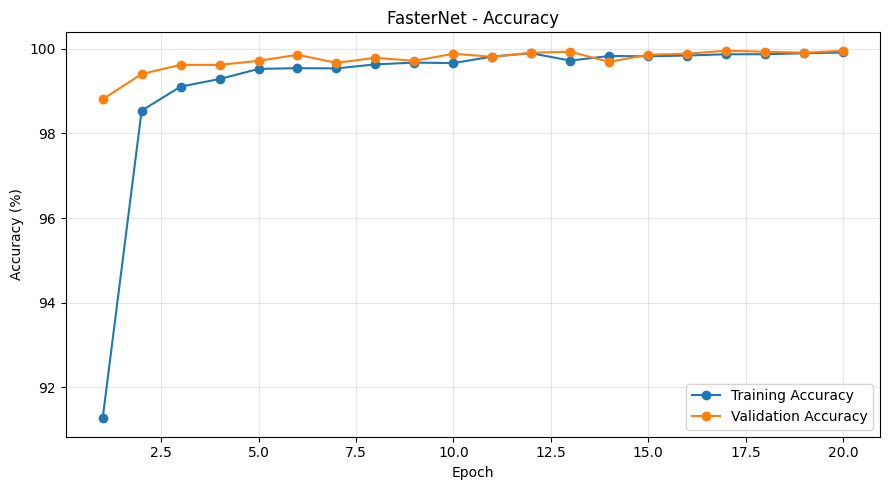

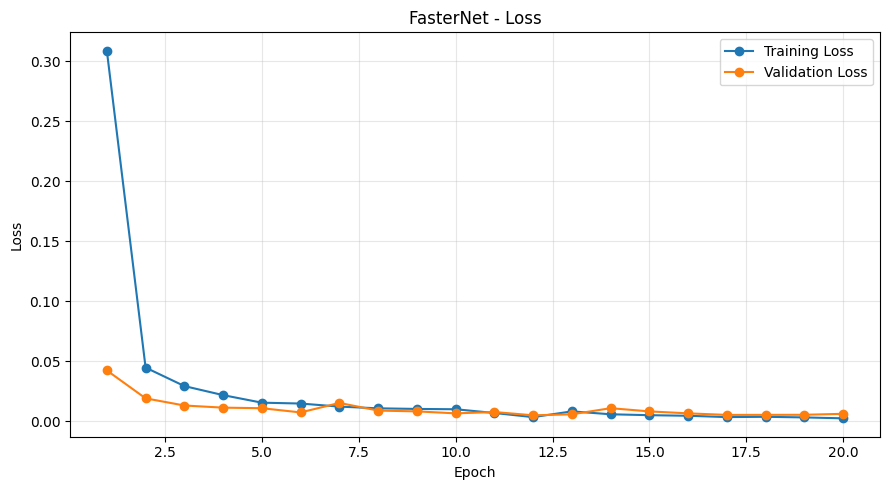

FasterNet: Both graphs saved successfully!


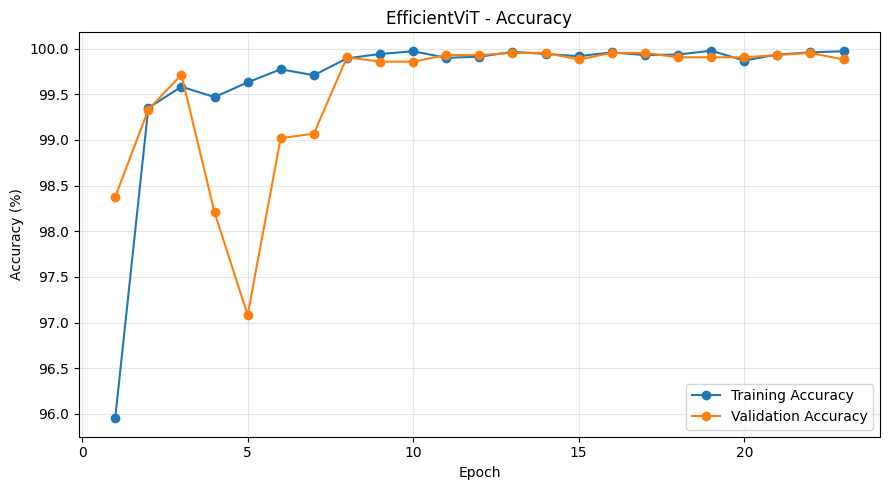

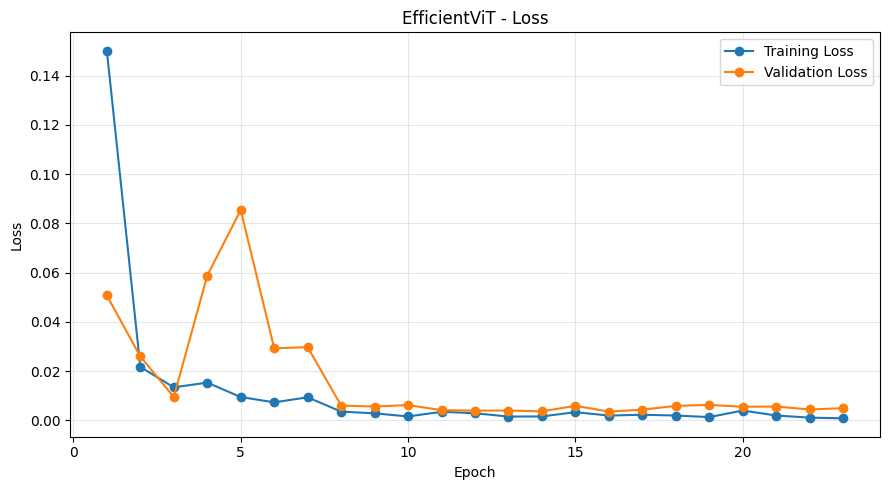

EfficientViT: Both graphs saved successfully!


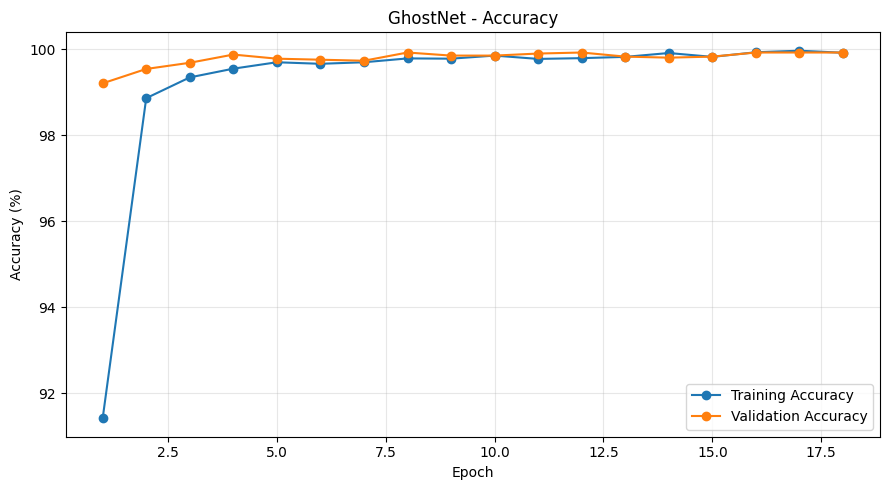

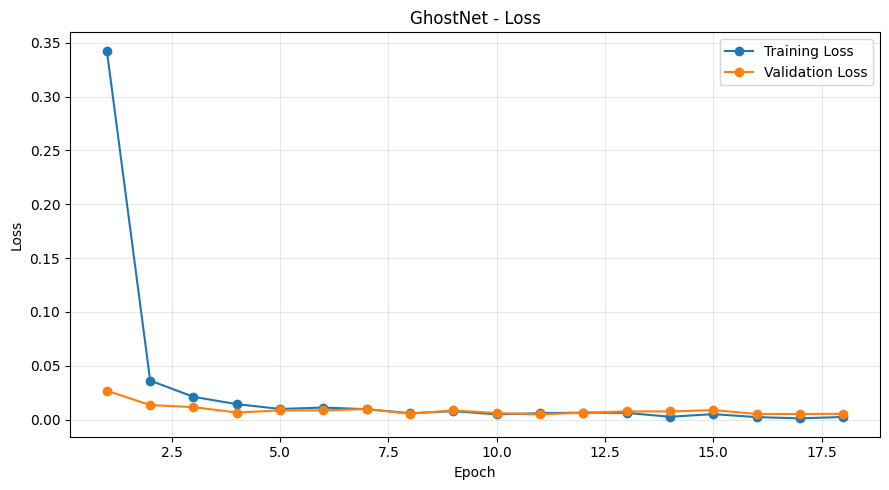

GhostNet: Both graphs saved successfully!

All six graphs saved to: /content/drive/MyDrive/C2_Training_Graphs


In [41]:

import matplotlib.pyplot as plt
from pathlib import Path

GRAPH_DIR = Path(
    "/content/drive/MyDrive/C2_Training_Graphs"
)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

for model_name, history in histories.items():

    epochs = range(1, len(history["train_loss"]) + 1)

    # Graph 1: Training and validation accuracy
    plt.figure(figsize=(9, 5))

    plt.plot(
        epochs,
        [acc * 100 for acc in history["train_accuracy"]],
        label="Training Accuracy",
        marker="o"
    )

    plt.plot(
        epochs,
        [acc * 100 for acc in history["val_accuracy"]],
        label="Validation Accuracy",
        marker="o"
    )

    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    accuracy_path = GRAPH_DIR / f"{model_name}_accuracy.png"
    plt.savefig(accuracy_path, dpi=300)
    plt.show()
    plt.close()

    # Graph 2: Training and validation loss
    plt.figure(figsize=(9, 5))

    plt.plot(
        epochs,
        history["train_loss"],
        label="Training Loss",
        marker="o"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss",
        marker="o"
    )

    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    loss_path = GRAPH_DIR / f"{model_name}_loss.png"
    plt.savefig(loss_path, dpi=300)
    plt.show()
    plt.close()

    print(f"{model_name}: Both graphs saved successfully!")

print("\nAll six graphs saved to:", GRAPH_DIR)


In [42]:

import pandas as pd
import torch

results = []

for model_name in ["FasterNet", "EfficientViT", "GhostNet"]:

    best_path = CHECKPOINT_DIR / f"{model_name.lower()}_best.pth"
    latest_path = CHECKPOINT_DIR / f"{model_name.lower()}_latest.pth"

    best = torch.load(
        best_path,
        map_location="cpu",
        weights_only=False
    )

    latest = torch.load(
        latest_path,
        map_location="cpu",
        weights_only=False
    )

    results.append({
        "Model": model_name,
        "Epochs Trained": latest["epoch"],
        "Best Epoch": best["epoch"],
        "Best Validation Accuracy (%)": round(
            best["val_accuracy"] * 100, 2
        ),
        "Best Validation Loss": round(
            best["val_loss"], 4
        )
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

# Save comparison to Google Drive
comparison_path = (
    "/content/drive/MyDrive/C2_Model_Comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\nComparison table saved successfully!")
print("Location:", comparison_path)


,Model,Epochs Trained,Best Epoch,Best Validation Accuracy (%),Best Validation Loss
0,FasterNet,20,12,99.90,0.0049
1,EfficientViT,23,16,99.95,0.0035
2,GhostNet,18,11,99.90,0.0048



Comparison table saved successfully!
Location: /content/drive/MyDrive/C2_Model_Comparison.csv


In [43]:

from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

checkpoint_dir = DRIVE_ROOT / "C2_Model_Checkpoints"
graph_dir = DRIVE_ROOT / "C2_Training_Graphs"
comparison_file = DRIVE_ROOT / "C2_Model_Comparison.csv"

models = ["FasterNet", "EfficientViT", "GhostNet"]

missing_files = []

print("=== MODEL CHECKPOINTS ===")

for model in models:
    for checkpoint_type in ["best", "latest"]:
        path = checkpoint_dir / f"{model.lower()}_{checkpoint_type}.pth"
        status = "SAVED" if path.is_file() else "MISSING"
        print(f"{path.name}: {status}")
        if not path.is_file():
            missing_files.append(str(path))

print("\n=== TRAINING GRAPHS ===")

for model in models:
    for graph_type in ["accuracy", "loss"]:
        path = graph_dir / f"{model}_{graph_type}.png"
        status = "SAVED" if path.is_file() else "MISSING"
        print(f"{path.name}: {status}")
        if not path.is_file():
            missing_files.append(str(path))

print("\n=== COMPARISON TABLE ===")
print(
    "C2_Model_Comparison.csv:",
    "SAVED" if comparison_file.is_file() else "MISSING"
)

if not comparison_file.is_file():
    missing_files.append(str(comparison_file))

print("\n=== FINAL STATUS ===")

if not missing_files:
    print("SUCCESS! All 13 C2 output files are saved.")
else:
    print(f"{len(missing_files)} files are missing.")
    for path in missing_files:
        print("Missing:", path)


=== MODEL CHECKPOINTS ===
fasternet_best.pth: SAVED
fasternet_latest.pth: SAVED
efficientvit_best.pth: SAVED
efficientvit_latest.pth: SAVED
ghostnet_best.pth: SAVED
ghostnet_latest.pth: SAVED

=== TRAINING GRAPHS ===
FasterNet_accuracy.png: SAVED
FasterNet_loss.png: SAVED
EfficientViT_accuracy.png: SAVED
EfficientViT_loss.png: SAVED
GhostNet_accuracy.png: SAVED
GhostNet_loss.png: SAVED

=== COMPARISON TABLE ===
C2_Model_Comparison.csv: SAVED

=== FINAL STATUS ===
SUCCESS! All 13 C2 output files are saved.


In [44]:

from pathlib import Path
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive")
FINAL_DIR = DRIVE_ROOT / "C2_Final_Deliverables"

(FINAL_DIR / "checkpoints").mkdir(
    parents=True, exist_ok=True
)
(FINAL_DIR / "graphs").mkdir(
    parents=True, exist_ok=True
)
(FINAL_DIR / "code").mkdir(
    parents=True, exist_ok=True
)

# Copy model checkpoints
for path in (DRIVE_ROOT / "C2_Model_Checkpoints").glob("*.pth"):
    shutil.copy2(path, FINAL_DIR / "checkpoints" / path.name)

# Copy training graphs
for path in (DRIVE_ROOT / "C2_Training_Graphs").glob("*.png"):
    shutil.copy2(path, FINAL_DIR / "graphs" / path.name)

# Copy comparison table
shutil.copy2(
    DRIVE_ROOT / "C2_Model_Comparison.csv",
    FINAL_DIR / "C2_Model_Comparison.csv"
)

print("Final folder created successfully!")
print("Location:", FINAL_DIR)

for folder in ["checkpoints", "graphs", "code"]:
    files = list((FINAL_DIR / folder).iterdir())
    print(f"{folder}: {len(files)} files")

print(
    "Comparison table:",
    (FINAL_DIR / "C2_Model_Comparison.csv").exists()
)


Final folder created successfully!
Location: /content/drive/MyDrive/C2_Final_Deliverables
checkpoints: 6 files
graphs: 6 files
code: 0 files
Comparison table: True
